# Bellman operators and certified planning

Discounted value iteration is a contraction; its Bellman residual yields a value error bound. Policy evaluation is a linear solve. Primal Bellman and dual occupancy linear programs supply independent optimal-value checks. Finite-horizon control instead uses a time-indexed policy.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src/decision_lab').is_dir()
sys.path.insert(0, str(ROOT / 'src'))
def read(path): return json.loads((ROOT / path).read_text())


## A one-state analytical oracle

In [2]:
from decision_lab.mdp import FiniteMDP, value_iteration, policy_iteration, bellman_lp, finite_horizon
mdp = FiniteMDP(np.ones((1,1,1)), np.ones((1,1)))
vi = value_iteration(mdp, .9)
pi = policy_iteration(mdp, .9)
lp = bellman_lp(mdp, .9)
assert abs(vi["value"][0]-10) <= vi["error_bound"]+1e-10
assert np.allclose(pi["value"], lp["value"])
vh, ph = finite_horizon(mdp, 5)
assert vh[0,0] == 5
print(vi["value"], vi["error_bound"])

[10.] 8.577316634728051e-10


## Main project certificates

In [3]:
pd.DataFrame(read("results/reference/planning/metrics.json")["rows"])[["profile","VI_iterations","PI_iterations","VI_value_error_bound","VI_PI_max_value_difference","discounted_primal_dual_gap"]]

,profile,VI_iterations,PI_iterations,VI_value_error_bound,VI_PI_max_value_difference,discounted_primal_dual_gap
0,per_user,2313,2,9.821122e-09,9.819516e-09,2.017941e-12
1,global,2312,2,9.873702e-09,9.873204e-09,3.424816e-12


## Rebuild the residual plot

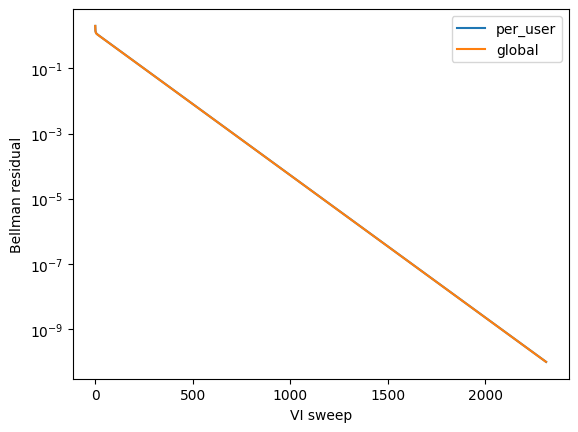

In [4]:
data = np.load(ROOT / "assets/source_data/planning.npz")
for profile in ["per_user","global"]: plt.semilogy(data[f"{profile}_VI_residual"],label=profile)
plt.xlabel("VI sweep"); plt.ylabel("Bellman residual"); plt.legend(); plt.show()

Full fits: `decision-lab planning --seed 0` (repeat seeds 1 and 2 where applicable). See [protocol](../docs/protocol.md), [results](../docs/results.md) and [references](../docs/references.md). These cells are numerical checks and evidence readers, not replacement training budgets.